In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [56]:
df = pd.read_csv("/Users/joelbannerman/Downloads/Bells Palsy Clinical Trial.csv")

#Changing Sex to dummy variables, Male = 1, Female = 0
df["Sex"]= (df["Sex"] == "Male").astype(int)

#Changing Within 24 hr to 0, >24 to ≤48 hr to 1, >48 to ≤72 hr to 2, REMOVED the Unknown
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].replace({"Within 24 hr": 0, ">24 to ≤48 hr": 1, ">48 to ≤72 hr": 2})
df = df[df["Time between onset of symptoms and start of treatment"] != "Unknown"]

#Changing Placebo-Placebo to 0, Acyclovir–Placebo to 1, Prednisolone–Placebo to 2, Acyclovir–Prednisolone to 3
#df["Treatment Group"] = df["Treatment Group"].replace({"Placebo–Placebo": 0, "Acyclovir–Placebo": 1, "Prednisolone–Placebo": 2, "Acyclovir–Prednisolone": 4})

#Changing Received Prednisolone to No = 0, Yes = 1 and Received Acyclovir to No = 0, Yes = 1
df["Received Prednisolone"] = df["Received Prednisolone"].replace({"Yes": 1, "No": 0})
df["Received Acyclovir"] = df["Received Acyclovir"].replace({"Yes": 1, "No": 0})

#Changing Full Recovery in 3 months to No = 0, Yes = 1 and Full Recovery in 9 months to No = 0, Yes = 1
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].replace({"No": 0, "Yes": 1})
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].replace({"No": 0, "Yes": 1})

#Dropping Treatment Group since its the same as received prednislone/acyclovir
df= df.drop("Treatment Group", axis = 1)

df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].astype(int)
df["Received Prednisolone"] = df["Received Prednisolone"].astype(int)
df["Received Acyclovir"] = df["Received Acyclovir"].astype(int)
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].astype(int)
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].astype(int)

#Drop NA Rows
df = df.dropna()
x = df[["Sex", "Age","Baseline Score on House–Brackmann scale", "Time between onset of symptoms and start of treatment", "Received Prednisolone", "Received Acyclovir"]]
y_1 = df["3-Month Score on House–Brackmann scale"]
y_2 = df["Full Recovery in 3 Months"]
y_3 = df["9-Month Score on House–Brackmann scale"]
y_4 = df["Full Recovery in 9 Months"]

/var/folders/_j/3k0_rrsd08j_j6bf25vqwxy40000gn/T/ipykernel_57180/2183817143.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Received Prednisolone"] = df["Received Prednisolone"].replace({"Yes": 1, "No": 0})
/var/folders/_j/3k0_rrsd08j_j6bf25vqwxy40000gn/T/ipykernel_57180/2183817143.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Received Acyclovir"] = df["Received Acyclovir"].replace({"Yes": 1, "No": 0})
/var/folders/_j/3k0_rrsd08j_j6bf25vqwxy40000gn/T/ipykernel_57180/2183817143.py:18: FutureWarning: Downcasting 

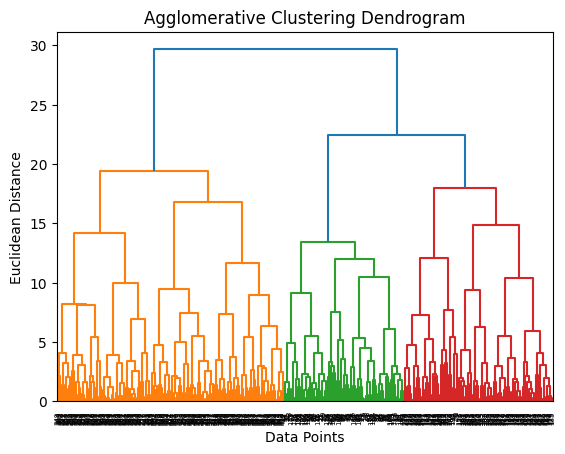

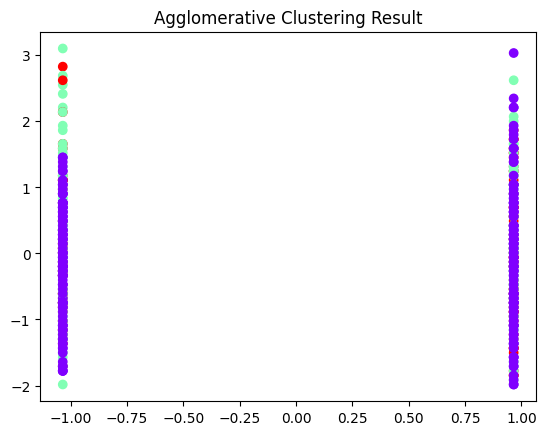

In [57]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(x)

# IL
sch.dendrogram(sch.linkage(scaled_data, method='ward'))
plt.title("Agglomerative Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
# Agglomerative Clustering (Bottom-Up Approach)
# Apply Agglomerative Clustering
n_k = 3 # Number of clusters
agg_clust = AgglomerativeClustering(n_clusters=n_k, linkage='ward')
agg_labels = agg_clust.fit_predict(scaled_data)

# Clustering on PCA
# Choose ONE to analyze

plt.figure()
plt.scatter(scaled_data[:, 0], scaled_data[:, 1], c=agg_labels, cmap= "rainbow")
plt.title("Agglomerative Clustering Result")
plt.show()

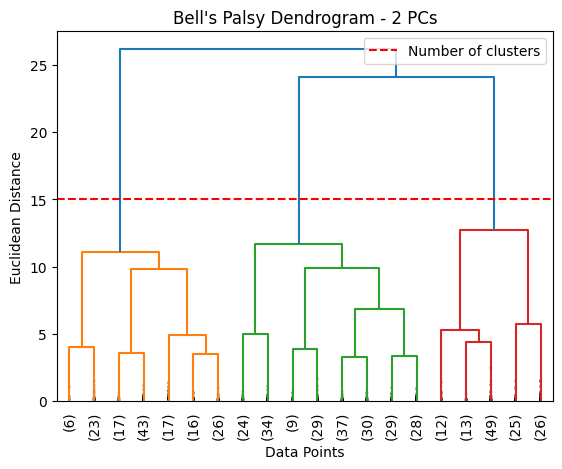

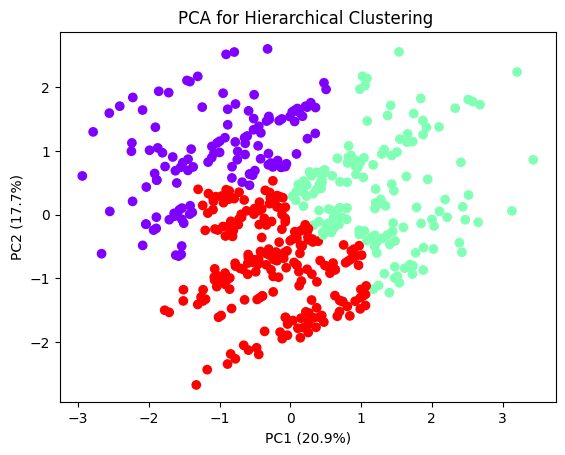

Explained Variance Ratio per Component: [0.20958947 0.17686464]
Cumulative Variance Ratio: [0.20958947 0.3864541 ]


In [72]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaled_data)
linkage_matrix = sch.linkage(X_pca, method= 'ward')
sch.dendrogram(
    linkage_matrix,
    truncate_mode='lastp',  # Only show the last p merged clusters
    p=20,                   # Adjust this number based on your needs
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True    # Shows dots where branches are collapsed
)

plt.axhline(y=15, color='r', linestyle='--', label=f'Number of clusters')
plt.title("Bell's Palsy Dendrogram - 2 PCs")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.legend()
plt.show()
# Agglomerative Clustering (Bottom-Up Approach)
# Apply Agglomerative Clustering
n_k = 3 # Number of clusters
agg_clust = AgglomerativeClustering(n_clusters=n_k, linkage='ward')
agg_labels = agg_clust.fit_predict(X_pca)

df["cluster"] = agg_labels   # or agg_labels_scaled

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap= "rainbow")
plt.title("PCA for Hierarchical Clustering ")
plt.xlabel('PC1 (20.9%)')
plt.ylabel('PC2 (17.7%)')
plt.show()

exp_var_ratio = pca.explained_variance_ratio_
cum_var_ratio = exp_var_ratio.cumsum()

print("Explained Variance Ratio per Component:", exp_var_ratio)
print("Cumulative Variance Ratio:", cum_var_ratio)



In [62]:
cluster_summary = df.groupby("cluster")[[
    "Sex",
    "Age",
    "Baseline Score on House–Brackmann scale",
    "Time between onset of symptoms and start of treatment",
    "Received Prednisolone",
    "Received Acyclovir",
    "Full Recovery in 3 Months",
    "Full Recovery in 9 Months",
    "3-Month Score on House–Brackmann scale",
    "9-Month Score on House–Brackmann scale"
]].mean()

print(cluster_summary)
print('-----------')
print(df["cluster"].value_counts())

              Sex        Age  Baseline Score on House–Brackmann scale  \
cluster                                                                 
0        0.424000  42.200000                                 3.280000   
1        0.371622  56.554054                                 4.621622   
2        0.668182  38.513636                                 3.272727   

         Time between onset of symptoms and start of treatment  \
cluster                                                          
0                                                 1.272000       
1                                                 0.385135       
2                                                 0.304545       

         Received Prednisolone  Received Acyclovir  Full Recovery in 3 Months  \
cluster                                                                         
0                     0.904000            0.480000                   0.840000   
1                     0.344595            0.445946          

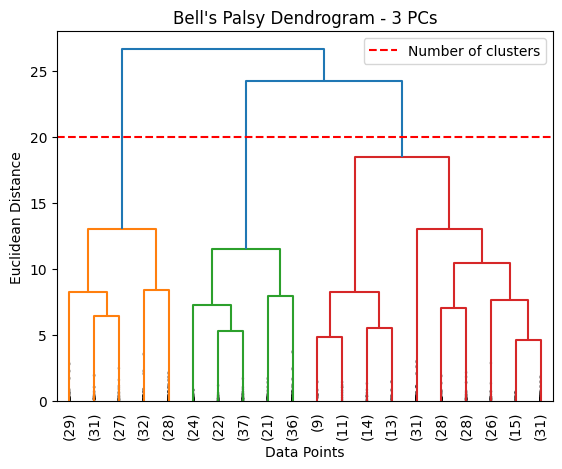

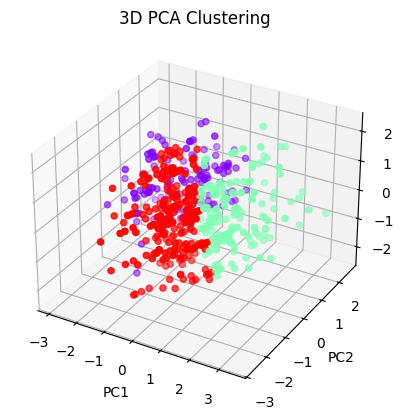

Explained Variance Ratio: [0.20958947 0.17686464 0.17006975]
Cumulative Variance: [0.20958947 0.3864541  0.55652385]


In [70]:
PCA2 = PCA(n_components=3)
X_PCA = PCA2.fit_transform(scaled_data)
linkage_matrix = sch.linkage(X_PCA, method= 'ward')
sch.dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
n_k = 3 # Number of clusters
agg_clust = AgglomerativeClustering(n_clusters=n_k, linkage='ward')
agg_labels = agg_clust.fit_predict(X_pca)

df["cluster"] = agg_labels   # or agg_labels_scaled

plt.axhline(y=20, color='r', linestyle='--', label=f'Number of clusters')
plt.title("Bell's Palsy Dendrogram - 3 PCs")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.legend()
plt.show()

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X_PCA[:, 0],
    X_PCA[:, 1],
    X_PCA[:, 2],
    c=agg_labels,
    cmap="rainbow"
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

plt.title("3D PCA Clustering")
plt.show()

print("Explained Variance Ratio:", PCA2.explained_variance_ratio_)
print("Cumulative Variance:", PCA2.explained_variance_ratio_.cumsum())

In [71]:
cluster_summary = df.groupby("cluster")[[
    "Sex",
    "Age",
    "Baseline Score on House–Brackmann scale",
    "Time between onset of symptoms and start of treatment",
    "Received Prednisolone",
    "Received Acyclovir",
    "Full Recovery in 3 Months",
    "Full Recovery in 9 Months",
    "3-Month Score on House–Brackmann scale",
    "9-Month Score on House–Brackmann scale"
]].mean()

print(cluster_summary)
print('-----------')
print(df["cluster"].value_counts())

              Sex        Age  Baseline Score on House–Brackmann scale  \
cluster                                                                 
0        0.424000  42.200000                                 3.280000   
1        0.371622  56.554054                                 4.621622   
2        0.668182  38.513636                                 3.272727   

         Time between onset of symptoms and start of treatment  \
cluster                                                          
0                                                 1.272000       
1                                                 0.385135       
2                                                 0.304545       

         Received Prednisolone  Received Acyclovir  Full Recovery in 3 Months  \
cluster                                                                         
0                     0.904000            0.480000                   0.840000   
1                     0.344595            0.445946          